In [1]:
import os
import sys
from datetime import date
from functools import partial

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

project_root = "/Users/elie/Documents/GitHub/quant_data/"
kf_dir = os.path.join(project_root, "personal", "Kalman_filter_spline")
sanos_kf_dir = os.path.join(project_root, "personal", "SANOS_KF_Strike")
for p in [project_root, kf_dir, sanos_kf_dir]:
    if p not in sys.path:
        sys.path.insert(0, p)

os.environ.setdefault("QUANTDATA_RAW_DATA", "/quantdata/raw")

from dlv_fit_absolute import SolverError, fit_density
from dlv_grid_absolute import make_density0, make_strike_grid
from dlv_pricing_absolute import (
    call_prices,
    iv_from_norm_call,
    iv_from_norm_put,
    option_prices,
    put_prices,
    v_atm_from_price,
)
from dlv_snapshot_absolute import make_batch_snapshots, run_intraday_loop

from personal.Kalman_filter_spline.surface_kalman_filters import build_iv_observations
from quantdata.massive.client import MassiveClient

%matplotlib inline
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

/Users/elie/Documents/GitHub/quant_data/quantdata/__init__.py:212: UserWarning: Using cache mode 'on' as specified in environment variable QUANTDATA_CACHE_MODE.


In [23]:
TICKER = "SPY"
TRADE_DATE = date(2024, 1, 3)
BATCH_FREQ = "1m"  # "1s" | "1m" | "5m"
MIN_TRADES = 100
N_VIZ = 6

# Geometry boundaries (fraction of the lowest / highest observed anchor)
LOWER_SCALE = 0.9  # lower boundary = LOWER_SCALE * min anchor
UPPER_SCALE = 1.1  # upper boundary = UPPER_SCALE * max anchor
DLV_MIN = 0.001
DLV_MAX = 2.0  # large: short-dated options need DLV ~ strike_range/T ~ 10+
CALLS_ONLY = False  # skip puts entirely; no PCP conversion
PUTS_ONLY = True  # skip calls entirely; only use puts
REGULARIZER_WEIGHT = 1e-6  # second-difference (log_dlv_space=False) or log-barrier (True) weight
LOG_DLV_SPACE = False  # True → log-barrier regularizer  −λ·Σlog(dᵢ);  False → legacy second-diff
TEMPORAL_REGULARIZER_WEIGHT = 1.0  # λ_T · Σᵢ((dᵢ−d̂ᵢ)/d̂ᵢ)²; 0.0 = off
TEMPORAL_WEIGHT_CLIP = 100.0  # caps weight ratio at C; floor = mean(d̂)/C; raise to allow more extremes, inf for no clipping

BID_ASK_PENALTY_WEIGHT = (
    0.0  # 1e10  # quadratic penalty for prices outside bid-ask (0 = off, try 1e4–1e6)
)

In [24]:
df_tickers = pl.read_csv(os.path.join(project_root, "personal", "spy_options_tickers.csv"))

client = MassiveClient()
df_spy = client.fetch_trades(TICKER, TRADE_DATE)

df_quotes_all, df_trades_all = build_iv_observations(
    df_tickers, TRADE_DATE, df_spy, min_trades=MIN_TRADES
)

print(f"quotes: {len(df_quotes_all):,}   trades: {len(df_trades_all):,}")
print("columns:", df_quotes_all.columns)
df_quotes_all.head(3)

Skipping O:SPY240105C00481000: 46 bad quotes
Skipping O:SPY240105C00482000: 64 bad quotes
Skipping O:SPY240105C00483000: 842 bad quotes
Skipping O:SPY240105C00484000: 2129 bad quotes
Skipping O:SPY240105C00485000: 3888 bad quotes
Skipping O:SPY240105P00462500: 17 bad quotes
Expiry 2024-01-05: implied forward from 13 strike(s)
quotes: 2,115,510   trades: 74,099
columns: ['ts_ns', 'strike', 'is_call', 'log_moneyness', 'T', 'observed_iv', 'bid_iv', 'ask_iv', 'R_iv', 'bid_price', 'ask_price', 'forward', 'discount_factor']


ts_ns,strike,is_call,log_moneyness,T,observed_iv,bid_iv,ask_iv,R_iv,bid_price,ask_price,forward,discount_factor
"datetime[ns, America/New_York]",f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.006781440 EST,479.0,true,0.018053,0.006217,0.13695,0.134075,0.139497,0.000007,0.09,0.11,470.43,null
2024-01-03 09:30:00.008294144 EST,471.0,false,0.001211,0.006217,0.127732,0.126371,0.129092,0.000002,2.17,2.21,470.43,null
2024-01-03 09:30:00.008340992 EST,479.0,true,0.018053,0.006217,0.138195,0.131123,0.144509,0.000045,0.08,0.13,470.43,null


In [25]:
df_quotes_all = df_quotes_all.drop_nulls()

In [26]:
df_quotes_all["discount_factor"]

discount_factor
f64
1.002
1.002
1.002
1.002
1.002
…
1.0
1.0
1.0


In [27]:
# Normalize prices by df only (not F*df) — absolute-strike variant.
# pure_strike = absolute dollar strike; bid_norm/ask_norm = C/df or P/df.
has_df = "discount_factor" in df_quotes_all.columns
df_scale = pl.col("discount_factor") if has_df else pl.lit(1.0)

df_q = df_quotes_all.with_columns(
    (pl.col("bid_price") / df_scale).alias("bid_norm"),
    (pl.col("ask_price") / df_scale).alias("ask_norm"),
    ((pl.col("bid_price") + pl.col("ask_price")) / 2.0 / df_scale).alias("mid_norm"),
    pl.col("strike").alias("pure_strike"),  # absolute dollar strikes (not K/F)
)

df_calls = df_q.filter(pl.col("is_call"))
df_puts = df_q.filter(~pl.col("is_call"))

tte_y_max = float(df_q["T"].max())
tte_y_med = float(df_q["T"].median())
print(f"calls: {len(df_calls):,}   puts: {len(df_puts):,}")
print(f"T range: [{df_q['T'].min():.5f}, {tte_y_max:.5f}]  median={tte_y_med:.5f}")
print(f"bid_norm null count: {df_q['bid_norm'].null_count()}")

calls: 956,381   puts: 1,159,090
T range: [0.00545, 0.00622]  median=0.00582
bid_norm null count: 0


In [28]:
# Build strike grid and initial density in absolute strike space.
#
# Padding anchor rationale is the same as the normalized version:
# dlvbox=0 pins at the first/last interior anchor. One padding anchor
# per side absorbs the pin so every observed strike has full DLV freedom.

tte_geom = tte_y_max * 1.1

df_anchor = df_puts if PUTS_ONLY else df_calls
ref_fwd = float(df_anchor["forward"].median())

abs_strikes = np.sort(df_anchor["strike"].unique().to_numpy().astype(float))
obs_ks = abs_strikes  # absolute dollar strikes — no division by ref_fwd

N_PAD = 1
grid = make_strike_grid(
    obs_ks, fwd=ref_fwd, lower_scale=LOWER_SCALE, upper_scale=UPPER_SCALE, n_pad=N_PAD
)
xstrikes_row = grid["xstrikes_row"]
anchor_pure = grid["anchor_pure"]  # absolute K values
interior_pure = grid["interior_pure"]
# log-moneyness axes for visualization (divide absolute K by reference forward)
anchor_lk = np.log(anchor_pure / ref_fwd)
interior_lk = np.log(interior_pure / ref_fwd)

grid_K, density0 = make_density0(xstrikes_row, fwd=ref_fwd)

_fit_fn = partial(
    fit_density,
    xstrikes_row=xstrikes_row,
    grid_K=grid_K,
    density0=density0,
    tte_geom=tte_geom,
    dlv_min=DLV_MIN,
    dlv_max=DLV_MAX,
    regularizer_weight=REGULARIZER_WEIGHT,
    log_dlv_space=LOG_DLV_SPACE,
    temporal_regularizer_weight=TEMPORAL_REGULARIZER_WEIGHT,
    temporal_weight_clip=TEMPORAL_WEIGHT_CLIP,
    bid_ask_penalty_weight=BID_ASK_PENALTY_WEIGHT,
    # fwd is NOT bound here — run_intraday_loop passes it per snapshot
)

print(f"Grid: N={len(grid_K)} interior anchors + 2 boundaries")
print(f"  ref_fwd: {ref_fwd:.4f}")
print(
    f"  {len(obs_ks)} observed strikes + {2 * N_PAD} pads → {len(anchor_pure)} interior anchors + 2 boundaries"
)
print(f"  anchor range:   [{anchor_pure[0]:.2f}, {anchor_pure[-1]:.2f}]  (dollars)")
print(f"  interior range: [{interior_pure[0]:.2f}, {interior_pure[-1]:.2f}]  (dollars)")
print(f"  dlvbox=0 pins at: {anchor_pure[0]:.2f} (lo_pad) and {anchor_pure[-1]:.2f} (hi_pad)")
print(f"  regularizer_weight: {REGULARIZER_WEIGHT}  log_dlv_space: {LOG_DLV_SPACE}")
print(
    f"  temporal_regularizer_weight: {TEMPORAL_REGULARIZER_WEIGHT}  temporal_weight_clip: {TEMPORAL_WEIGHT_CLIP}"
)
print(f"  bid_ask_penalty_weight: {BID_ASK_PENALTY_WEIGHT}")

Grid: N=23 interior anchors + 2 boundaries
  ref_fwd: 470.0180
  21 observed strikes + 2 pads → 23 interior anchors + 2 boundaries
  anchor range:   [427.50, 500.85]  (dollars)
  interior range: [450.00, 477.00]  (dollars)
  dlvbox=0 pins at: 427.50 (lo_pad) and 500.85 (hi_pad)
  regularizer_weight: 1e-06  log_dlv_space: False
  temporal_regularizer_weight: 1.0  temporal_weight_clip: 100.0
  bid_ask_penalty_weight: 0.0


In [29]:
snaps_calls = make_batch_snapshots(df_calls, BATCH_FREQ)
snaps_puts = make_batch_snapshots(df_puts, BATCH_FREQ)

snap_ref = snaps_puts if PUTS_ONLY else snaps_calls
batch_ts_list = sorted(snap_ref["batch_ts"].unique().to_list())
print(f"{len(batch_ts_list)} snapshots at {BATCH_FREQ} frequency")
print(f"first: {batch_ts_list[0]}   last: {batch_ts_list[-1]}")

405 snapshots at 1m frequency
first: 2024-01-03 09:30:00-05:00   last: 2024-01-03 16:14:00-05:00


In [30]:
try:
    from tqdm.auto import tqdm
except ImportError:

    def tqdm(x, **kw):
        return x


results = run_intraday_loop(
    batch_ts_list=tqdm(batch_ts_list, desc="Fitting snapshots"),
    snaps_calls=snaps_calls,
    snaps_puts=snaps_puts,
    fit_fn=_fit_fn,
    tte_y_med=tte_y_med,
    calls_only=CALLS_ONLY,
    puts_only=PUTS_ONLY,
    verbose=True,
)

good = [r for r in results if not r["failed"]]
n_failed = sum(r["failed"] for r in results)
print(f"Done.  Failed: {n_failed}/{len(results)}")

Done.  Failed: 0/405


In [31]:
# ── Observed-range diagnostics — unconstrained zone width ─────────────────
# K_lo_obs / K_hi_obs are now absolute dollar strikes.
# Martingale residual is |Σ Kᵢdᵢ − F| / F (relative, dimensionless).

import pandas as pd

rows = []
for r in results:
    if r["failed"] or r["densities"] is None:
        continue
    k_lo = r.get("K_lo_obs", float("nan"))
    k_hi = r.get("K_hi_obs", float("nan"))
    d = r["densities"][0]
    fwd_r = r["fwd"]
    mart = float(np.abs(anchor_pure @ d - fwd_r) / fwd_r)  # relative residual
    rows.append(
        dict(
            ts=r["ts"],
            K_lo_obs=k_lo,
            K_hi_obs=k_hi,
            martingale_residual=mart,
        )
    )

df_diag = pd.DataFrame(rows)
print(df_diag[["ts", "K_lo_obs", "K_hi_obs", "martingale_residual"]].to_string())
print(f"\nmean K_lo_obs (dollars):  {df_diag['K_lo_obs'].mean():.2f}")
print(f"mean K_hi_obs (dollars):  {df_diag['K_hi_obs'].mean():.2f}")
print(f"max martingale residual:  {df_diag['martingale_residual'].max():.2e}")

# Show which interior anchors fall in the extrapolated zone
if PUTS_ONLY:
    median_k_bound = float(df_diag["K_hi_obs"].median())
    extrap_mask = interior_pure >= median_k_bound
    extrap_label = f"K ≥ {median_k_bound:.2f}"
else:
    median_k_bound = float(df_diag["K_lo_obs"].median())
    extrap_mask = interior_pure <= median_k_bound
    extrap_label = f"K ≤ {median_k_bound:.2f}"

print(
    f"\nExtrapolated interior anchors ({extrap_label}): {extrap_mask.sum()} of {len(interior_pure)}"
)
print(f"  K values (dollars): {np.round(interior_pure[extrap_mask], 2)}")

                           ts  K_lo_obs  K_hi_obs  martingale_residual
0   2024-01-03 09:30:00-05:00     450.0     477.0         7.908378e-12
1   2024-01-03 09:31:00-05:00     450.0     477.0         0.000000e+00
2   2024-01-03 09:32:00-05:00     450.0     477.0         1.208044e-16
3   2024-01-03 09:33:00-05:00     450.0     477.0         0.000000e+00
4   2024-01-03 09:34:00-05:00     450.0     477.0         1.208113e-16
5   2024-01-03 09:35:00-05:00     450.0     477.0         1.207812e-16
6   2024-01-03 09:36:00-05:00     450.0     477.0         1.208159e-16
7   2024-01-03 09:37:00-05:00     458.0     477.0         2.416196e-16
8   2024-01-03 09:38:00-05:00     450.0     477.0         2.415888e-16
9   2024-01-03 09:39:00-05:00     450.0     477.0         1.208072e-16
10  2024-01-03 09:40:00-05:00     450.0     477.0         1.207967e-16
11  2024-01-03 09:41:00-05:00     459.0     477.0         1.207379e-16
12  2024-01-03 09:42:00-05:00     459.0     477.0         0.000000e+00
13  20

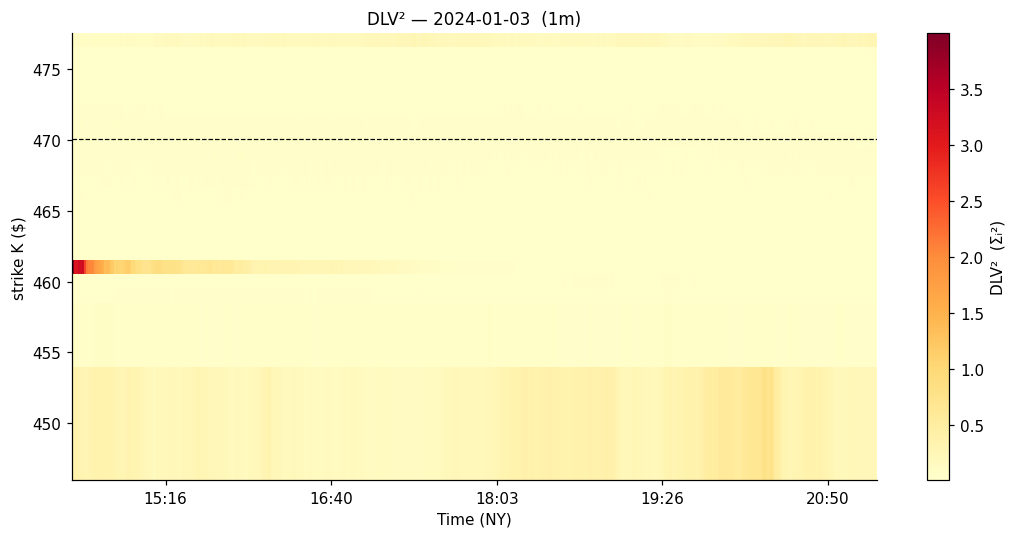

In [32]:
# ── DLV² heatmap ─────────────────────────────────────────────────────────

import datetime as _dt

from matplotlib.ticker import FuncFormatter

fmt = FuncFormatter(lambda x, _: _dt.datetime.fromtimestamp(x).strftime("%H:%M"))


def _ts_num(r):
    return r["ts"].timestamp() if hasattr(r["ts"], "timestamp") else float(r["ts"]) / 1e9


fig, ax = plt.subplots(1, 1, figsize=(10, 5))

if not good:
    ax.set_title("DLV² — no data", fontsize=11)
else:
    n = len(good)
    mat = np.full((len(interior_pure), n), np.nan)
    ts_nums = np.empty(n)
    for j, r in enumerate(good):
        mat[:, j] = r["dlvsqs"][0]
        ts_nums[j] = _ts_num(r)
    pcm = ax.pcolormesh(ts_nums, interior_pure, mat, cmap="YlOrRd", shading="nearest")
    fig.colorbar(pcm, ax=ax, label="DLV²  (Σᵢ²)")
    ax.xaxis.set_major_formatter(fmt)
    ax.set_xlabel("Time (NY)")
    ax.set_ylabel("strike K ($)")
    ax.set_title(f"DLV² — {TRADE_DATE}  ({BATCH_FREQ})", fontsize=11)
    ax.axhline(ref_fwd, color="black", lw=0.8, ls="--", label="ATM (ref_fwd)")

plt.tight_layout()
plt.show()

In [33]:
(mat >= 3.9).sum() / mat.shape[0] / mat.shape[1]

np.float64(0.00011757789535567312)

In [34]:
# ── DLV² heatmap (plotly) ────────────────────────────────────────────────

import datetime as _dt

import numpy as np
import plotly.graph_objects as go


def _ts_num(r):
    return r["ts"].timestamp() if hasattr(r["ts"], "timestamp") else float(r["ts"]) / 1e9


if not good:
    fig = go.Figure()
    fig.update_layout(title="DLV² — no data", width=1000, height=500)
else:
    n = len(good)
    mat = np.full((len(interior_pure), n), np.nan)
    ts = np.empty(n, dtype=object)
    for j, r in enumerate(good):
        mat[:, j] = r["dlvsqs"][0]
        ts[j] = _dt.datetime.fromtimestamp(_ts_num(r))

    fig = go.Figure(
        go.Heatmap(
            x=ts,
            y=interior_pure,
            z=mat,
            colorscale="YlOrRd",
            colorbar=dict(title="DLV²  (Σᵢ²)"),
            hovertemplate=("t=%{x|%H:%M}<br>K=%{y:.2f}<br>DLV²=%{z:.4g}<extra></extra>"),
        )
    )
    fig.add_hline(y=ref_fwd, line=dict(color="black", width=0.8, dash="dash"))
    fig.update_layout(
        title=f"DLV² — {TRADE_DATE}  ({BATCH_FREQ})",
        xaxis_title="Time (NY)",
        yaxis_title="strike K ($)",
        width=1000,
        height=500,
    )
    fig.update_xaxes(tickformat="%H:%M")

fig.show()

In [35]:
mat.mean()

np.float64(0.05170373808323091)

In [36]:
# ── Risk-neutral density q heatmap ───────────────────────────────────────
import datetime as _dt
from zoneinfo import ZoneInfo

import plotly.graph_objects as go

_ny = ZoneInfo("America/New_York")

if not good:
    fig = go.Figure()
    fig.update_layout(title="Density q — no data")
else:
    n = len(good)
    mat = np.full((len(anchor_pure), n), np.nan)
    ts_nums = np.empty(n)
    for j, r in enumerate(good):
        mat[:, j] = r["densities"][0]
        ts_nums[j] = _ts_num(r)

    x_dt = [_dt.datetime.fromtimestamp(t, tz=_ny) for t in ts_nums]
    log_mat = np.log(np.where(mat > 0, mat, np.nan))

    fig = go.Figure(
        go.Heatmap(
            x=x_dt,
            y=anchor_pure,
            z=log_mat,
            colorscale="YlOrRd",
            colorbar=dict(title="log(qᵢ)"),
        )
    )

    fig.add_hline(y=ref_fwd, line=dict(color="black", width=1, dash="dash"))

    fig.update_layout(
        title=f"Density q (log scale) — {TRADE_DATE}  ({BATCH_FREQ})",
        xaxis=dict(title="Time (NY)", tickformat="%H:%M"),
        yaxis=dict(title="strike K ($)"),
        width=900,
        height=450,
    )

fig

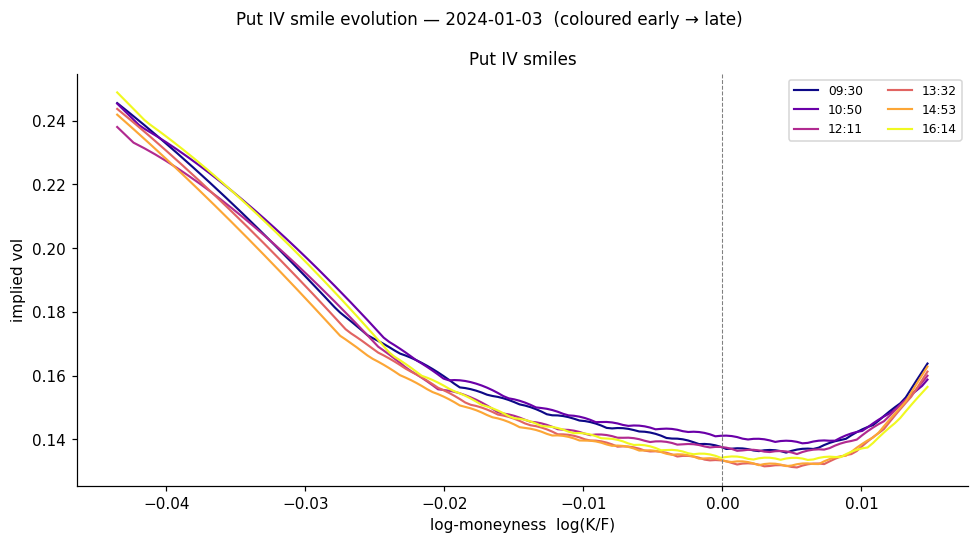

In [37]:
# ── Put/Call IV smile snapshots ───────────────────────────────────────────
# Dense grid in log-moneyness space; converted to absolute K for pricing.

obs_lk_lo = float(np.log(interior_pure[0] / ref_fwd))
obs_lk_hi = float(np.log(interior_pure[-1] / ref_fwd))

lk_dense = np.linspace(obs_lk_lo, obs_lk_hi, 150)

viz_indices = np.linspace(0, len(good) - 1, min(N_VIZ, len(good)), dtype=int)
colors = [plt.cm.plasma(i / max(len(viz_indices) - 1, 1)) for i in range(len(viz_indices))]

iv_fn = iv_from_norm_put if PUTS_ONLY else iv_from_norm_call
opt_type = "Put" if PUTS_ONLY else "Call"

fig, ax = plt.subplots(1, 1, figsize=(9, 5))
ax.set_title(f"{opt_type} IV smiles", fontsize=11)

for i, color in zip(viz_indices, colors):
    r = good[int(i)]
    label = r["ts"].strftime("%H:%M") if hasattr(r["ts"], "strftime") else str(r["ts"])
    fwd_r = r["fwd"]

    pk_dense = fwd_r * np.exp(lk_dense)  # absolute K for this snapshot's forward

    if PUTS_ONLY:
        prices = put_prices(r["densities"][0], grid_K, pk_dense, fwd=fwd_r)
    else:
        prices = call_prices(r["densities"][0], grid_K, pk_dense)

    ivs = np.array([iv_fn(float(p), float(k), r["T"], fwd_r) for p, k in zip(prices, lk_dense)])
    mask = np.isfinite(ivs) & (ivs > 0)
    ax.plot(lk_dense[mask], ivs[mask], color=color, lw=1.4, label=label)

ax.set_xlabel("log-moneyness  log(K/F)")
ax.set_ylabel("implied vol")
ax.axvline(0, color="gray", lw=0.7, ls="--")
ax.legend(fontsize=8, ncol=2)

fig.suptitle(f"{opt_type} IV smile evolution — {TRADE_DATE}  (coloured early → late)", fontsize=11)
plt.tight_layout()
plt.show()

In [38]:
# the left hump is an artifact of IV inversion.

In [39]:
ivs.max() - ivs.min()

np.float64(0.11529243533127911)

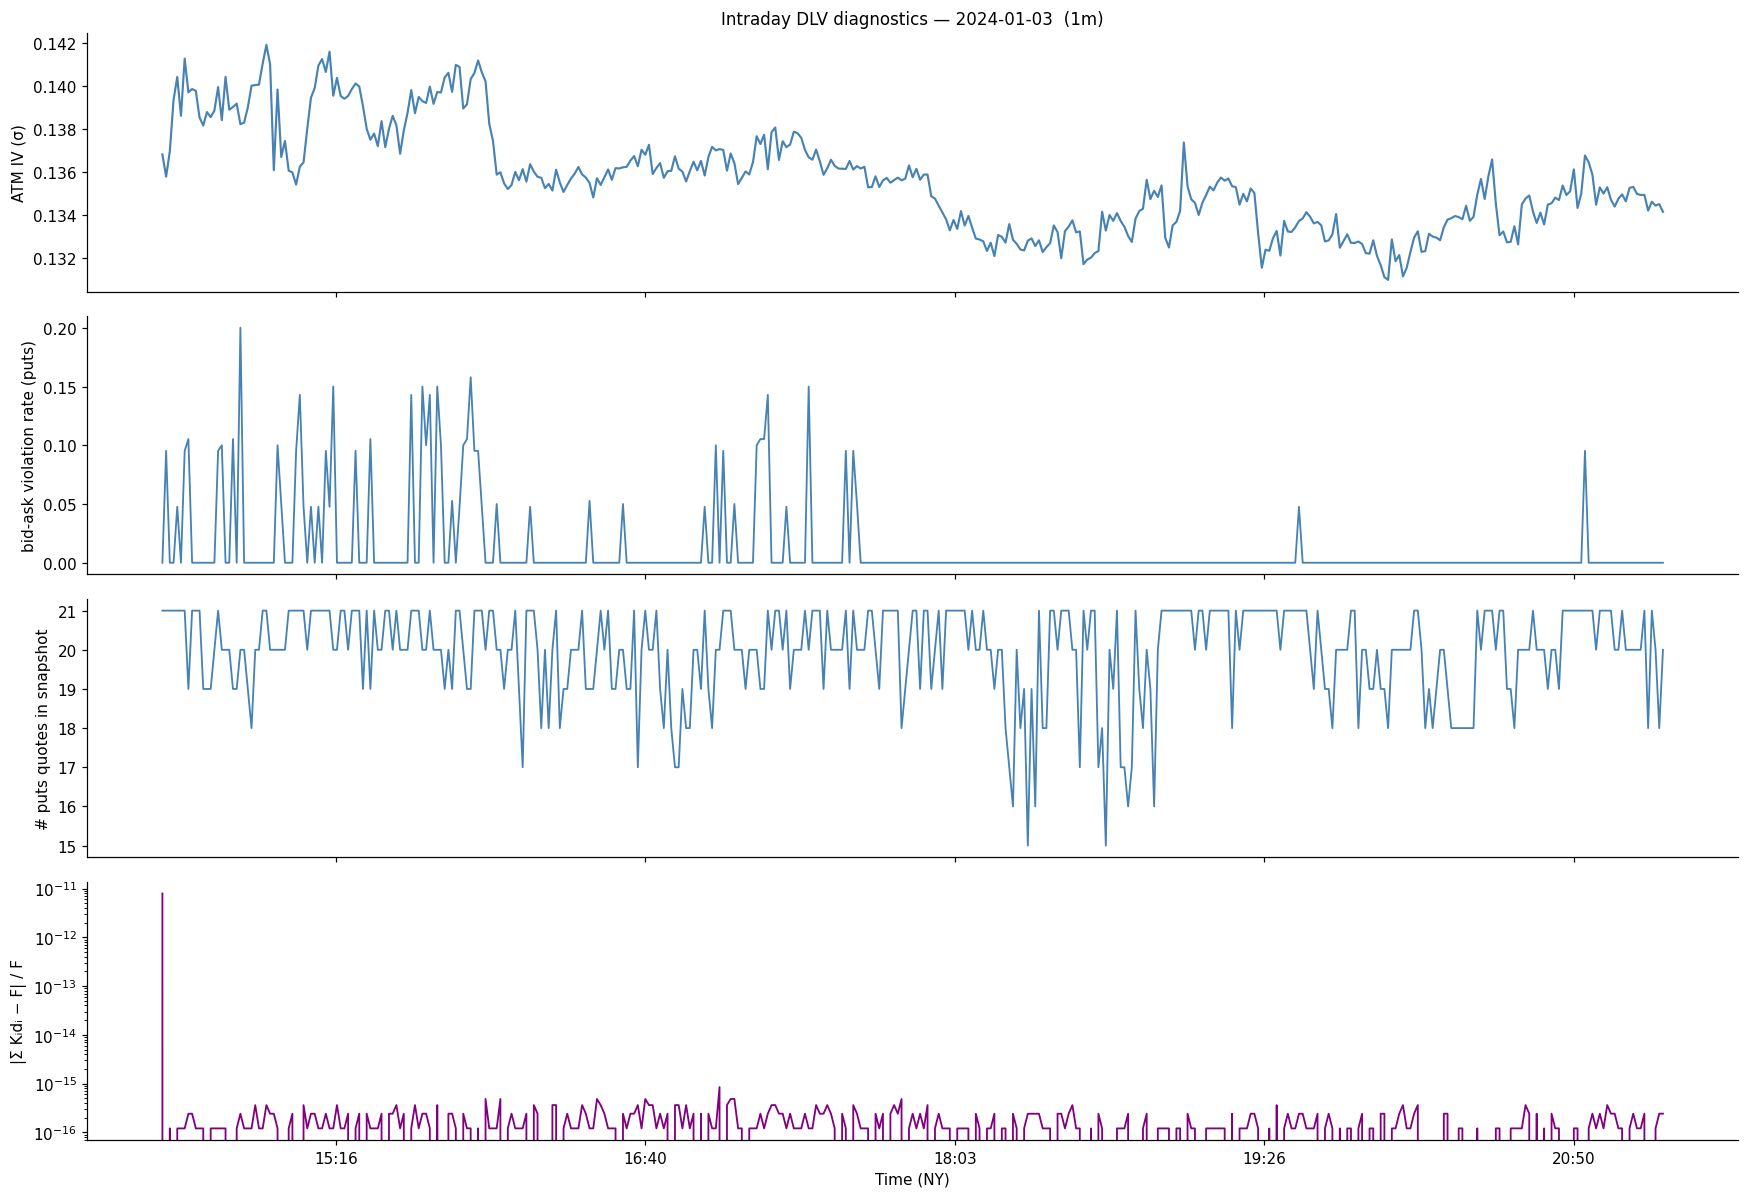

In [40]:
mart_res = []
for r in results:
    if r["densities"] is not None:
        d = r["densities"][0]
        fwd_r = r["fwd"]
        mart_res.append(float(np.abs(anchor_pure @ d - fwd_r) / fwd_r))
    else:
        mart_res.append(float("nan"))

# ── Fit quality metrics over time ─────────────────────────────────────────

ts_list, viol_obs, atm_iv_list, n_obs_list = [], [], [], []

for r in results:
    ts = r["ts"]
    snap_obs = (
        (snaps_puts if PUTS_ONLY else snaps_calls)
        .filter(pl.col("batch_ts") == ts)
        .sort("pure_strike")
    )

    ts_list.append(ts)
    atm_iv_list.append(r["atm_iv"])
    n_obs_list.append(r["n_puts"] if PUTS_ONLY else r["n_calls"])

    if r["densities"] is not None and not snap_obs.is_empty():
        pk_obs = snap_obs["pure_strike"].to_numpy().astype(float)
        bid_obs = snap_obs["bid_norm"].to_numpy().astype(float)
        ask_obs = snap_obs["ask_norm"].to_numpy().astype(float)
        is_call_arr = (
            np.zeros(len(pk_obs), dtype=bool) if PUTS_ONLY else np.ones(len(pk_obs), dtype=bool)
        )
        fit_obs = option_prices(r["densities"][0], grid_K, pk_obs, is_call_arr, fwd=r["fwd"])
        viol_obs.append(float(((fit_obs < bid_obs) | (fit_obs > ask_obs)).mean()))
    else:
        viol_obs.append(float("nan"))

ts_nums = np.array([t.timestamp() if hasattr(t, "timestamp") else float(t) / 1e9 for t in ts_list])

fig, axes = plt.subplots(4, 1, figsize=(16, 11), sharex=True)

axes[0].plot(ts_nums, atm_iv_list, color="steelblue", lw=1.4)
axes[0].set_ylabel("ATM IV (σ)")
axes[0].set_title(f"Intraday DLV diagnostics — {TRADE_DATE}  ({BATCH_FREQ})", fontsize=11)

opt_label = "puts" if PUTS_ONLY else "calls"
axes[1].plot(ts_nums, viol_obs, color="steelblue", lw=1.2)
axes[1].set_ylabel(f"bid-ask violation rate ({opt_label})")

axes[2].plot(ts_nums, n_obs_list, color="steelblue", lw=1.2)
axes[2].set_ylabel(f"# {opt_label} quotes in snapshot")

axes[3].semilogy(ts_nums, mart_res, color="purple", lw=1.2)
axes[3].set_ylabel("|Σ Kᵢdᵢ − F| / F")

for ax in axes:
    ax.xaxis.set_major_formatter(fmt)
axes[-1].set_xlabel("Time (NY)")
plt.tight_layout()
plt.show()

In [41]:
# ── SANOS vs call bid-ask: single snapshot ───────────────────────────────

import plotly.graph_objects as go

SNAP_IDX = 0  # which snapshot to display

r = good[SNAP_IDX]
fwd_r = r["fwd"]
label = r["ts"].strftime("%H:%M:%S") if hasattr(r["ts"], "strftime") else str(r["ts"])

# Dense curve grid: log-moneyness space → absolute K
lk_curve = np.linspace(anchor_lk[0] + 0.01, anchor_lk[-1] - 0.01, 250)
pk_curve = fwd_r * np.exp(lk_curve)  # absolute K for pricing

fig = go.Figure()

snap = (
    (snaps_puts if PUTS_ONLY else snaps_calls)
    .filter(pl.col("batch_ts") == r["ts"])
    .sort("pure_strike")
)

if not snap.is_empty() and r["densities"] is not None:
    pk_obs = snap["pure_strike"].to_numpy().astype(float)  # absolute K
    lk_obs = np.log(pk_obs / fwd_r)  # log-moneyness for x-axis
    bid = snap["bid_norm"].to_numpy().astype(float)
    ask = snap["ask_norm"].to_numpy().astype(float)

    is_call_arr = (
        np.zeros(len(pk_obs), dtype=bool) if PUTS_ONLY else np.ones(len(pk_obs), dtype=bool)
    )
    fit_obs = option_prices(r["densities"][0], grid_K, pk_obs, is_call_arr, fwd=fwd_r)
    inside = (fit_obs >= bid) & (fit_obs <= ask)
    viol_pct = f"{(~inside).mean():.0%}"

    if PUTS_ONLY:
        fit_curve = put_prices(r["densities"][0], grid_K, pk_curve, fwd=fwd_r)
    else:
        fit_curve = call_prices(r["densities"][0], grid_K, pk_curve)

    fig.add_trace(
        go.Scatter(
            x=lk_obs,
            y=ask,
            mode="lines+markers",
            line=dict(color="rgba(100,100,100,0.6)", width=1, dash="dot"),
            marker=dict(color="rgba(100,100,100,0.6)", size=4),
            name="ask",
            hovertemplate="lk=%{x:.4f}<br>ask=%{y:.5f}<extra>ask</extra>",
        )
    )
    fig.add_trace(
        go.Scatter(
            x=lk_obs,
            y=bid,
            mode="lines+markers",
            line=dict(color="rgba(100,100,100,0.6)", width=1, dash="dot"),
            marker=dict(color="rgba(100,100,100,0.6)", size=4),
            fill="tonexty",
            fillcolor="rgba(150,150,150,0.18)",
            name="bid (spread shaded)",
            hovertemplate="lk=%{x:.4f}<br>bid=%{y:.5f}<extra>bid</extra>",
        )
    )
    fig.add_trace(
        go.Scatter(
            x=lk_curve,
            y=fit_curve,
            mode="lines",
            line=dict(color="steelblue", width=2.5),
            name="SANOS fit",
            hovertemplate="lk=%{x:.4f}<br>SANOS=%{y:.5f}<extra>SANOS</extra>",
        )
    )
    if (~inside).any():
        fig.add_trace(
            go.Scatter(
                x=lk_obs[~inside],
                y=fit_obs[~inside],
                mode="markers",
                marker=dict(color="crimson", size=8, symbol="x-thin", line=dict(width=2)),
                name=f"violation ({viol_pct})",
                hovertemplate="lk=%{x:.4f}<br>fit=%{y:.5f}<extra>violation</extra>",
            )
        )

    fig.add_vline(x=0.0, line=dict(color="black", width=0.8, dash="dot"))

fig.update_xaxes(title_text="log(K/F)")
fig.update_yaxes(title_text="undiscounted option price (C/df)")
fig.update_layout(
    title=dict(
        text=f"SANOS vs call bid-ask  |  {label}  —  {TRADE_DATE}  ({BATCH_FREQ})",
        font=dict(size=13),
    ),
    width=850,
    height=500,
    legend=dict(orientation="h", yanchor="bottom", y=-0.20, x=0.5, xanchor="center"),
    template="simple_white",
)
fig.show()

Max density perturbation (5% quote jitter): 4.0449e-03  [threshold 1e-2]
PASS ✓


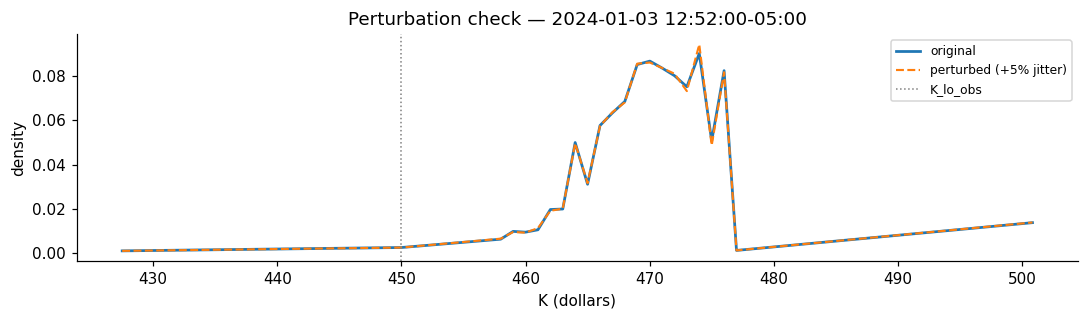

In [42]:
# ── Perturbation check: null space is resolved if the density is stable ─────
# Jitter quotes by ±5% of half-spread and confirm density doesn't jump.

r0 = good[len(good) // 2]
fwd_r0 = r0["fwd"]
snap_data = snaps_puts if PUTS_ONLY else snaps_calls
snap = snap_data.filter(pl.col("batch_ts") == r0["ts"]).sort("pure_strike")
pk = snap["pure_strike"].to_numpy().astype(float)  # absolute K
bid0 = snap["bid_norm"].to_numpy().astype(float)
ask0 = snap["ask_norm"].to_numpy().astype(float)
is_calls = np.zeros(len(pk), dtype=bool) if PUTS_ONLY else np.ones(len(pk), dtype=bool)

rng = np.random.default_rng(42)
half_sp = (ask0 - bid0) / 2.0
eps_j = rng.uniform(-0.05, 0.05, size=len(pk)) * half_sp
bid_j = np.maximum(1e-8, bid0 + eps_j)
ask_j = np.maximum(bid_j + 1e-6, ask0 + eps_j)

d0, _, _ = fit_density(
    bid_norm=bid0,
    ask_norm=ask0,
    pure_K=pk,
    is_calls=is_calls,
    xstrikes_row=xstrikes_row,
    grid_K=grid_K,
    density0=density0,
    tte_geom=tte_geom,
    fwd=fwd_r0,
    dlv_min=DLV_MIN,
    dlv_max=DLV_MAX,
    regularizer_weight=REGULARIZER_WEIGHT,
    log_dlv_space=LOG_DLV_SPACE,
    temporal_regularizer_weight=TEMPORAL_REGULARIZER_WEIGHT,
    temporal_weight_clip=TEMPORAL_WEIGHT_CLIP,
    bid_ask_penalty_weight=BID_ASK_PENALTY_WEIGHT,
)
d1, _, _ = fit_density(
    bid_norm=bid_j,
    ask_norm=ask_j,
    pure_K=pk,
    is_calls=is_calls,
    xstrikes_row=xstrikes_row,
    grid_K=grid_K,
    density0=density0,
    tte_geom=tte_geom,
    fwd=fwd_r0,
    dlv_min=DLV_MIN,
    dlv_max=DLV_MAX,
    regularizer_weight=REGULARIZER_WEIGHT,
    log_dlv_space=LOG_DLV_SPACE,
    temporal_regularizer_weight=TEMPORAL_REGULARIZER_WEIGHT,
    temporal_weight_clip=TEMPORAL_WEIGHT_CLIP,
    bid_ask_penalty_weight=BID_ASK_PENALTY_WEIGHT,
)

max_diff = float(np.max(np.abs(d0 - d1)))
print(f"Max density perturbation (5% quote jitter): {max_diff:.4e}  [threshold 1e-2]")
print(
    "PASS ✓" if max_diff < 0.01 else "WARNING: solution jumps — consider larger regularizer_weight"
)

# visualise — x-axis is absolute K (dollars)
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(anchor_pure, d0, label="original", lw=1.8)
ax.plot(anchor_pure, d1, "--", label="perturbed (+5% jitter)", lw=1.4)
ax.axvline(r0.get("K_lo_obs", float("nan")), color="grey", lw=1, ls=":", label="K_lo_obs")
ax.set_xlabel("K (dollars)")
ax.set_ylabel("density")
ax.set_title(f"Perturbation check — {r0['ts']}")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [43]:
# ── Bid-ask arbitrage-free feasibility check ─────────────────────────────
# For each snapshot, check via LP whether there exists any price curve within
# the observed spreads that is arb-free (convex in K; monotone: calls decrease,
# puts increase with K — no call/put-spread or butterfly arb).

import datetime as _dt
from zoneinfo import ZoneInfo

import plotly.graph_objects as go
from scipy.optimize import linprog

_ny = ZoneInfo("America/New_York")


def bid_ask_arb_free(strikes, bids, asks, is_call=True):
    """Return (feasible: bool, prices: array | None).

    LP feasibility: does there exist C_i with b_i <= C_i <= a_i that is
    convex in strike and monotone (calls: decreasing; puts: increasing)?
    """
    K = np.asarray(strikes, dtype=float)
    n = len(K)
    if n < 2:
        return True, np.asarray(bids, dtype=float)

    A_ub, b_ub = [], []

    # Monotonicity
    for i in range(n - 1):
        row = np.zeros(n)
        if is_call:
            row[i + 1] = 1.0  # C_{i+1} - C_i <= 0  (calls decrease with K)
            row[i] = -1.0
        else:
            row[i] = 1.0  # P_i - P_{i+1} <= 0  (puts increase with K)
            row[i + 1] = -1.0
        A_ub.append(row)
        b_ub.append(0.0)

    # Convexity (butterfly >= 0) at each interior point, unequal spacing
    for i in range(1, n - 1):
        dK_l = K[i] - K[i - 1]
        dK_r = K[i + 1] - K[i]
        dK = K[i + 1] - K[i - 1]
        row = np.zeros(n)
        row[i - 1] = -dK_r / dK
        row[i] = 1.0
        row[i + 1] = -dK_l / dK
        A_ub.append(row)
        b_ub.append(0.0)

    res = linprog(
        np.zeros(n),
        A_ub=np.array(A_ub),
        b_ub=np.array(b_ub),
        bounds=list(zip(bids, asks)),
        method="highs",
    )
    feasible = res.status == 0
    return feasible, res.x if feasible else None


# ── Run for every snapshot in batch_ts_list ───────────────────────────────
snap_data = snaps_puts if PUTS_ONLY else snaps_calls
opt_label = "puts" if PUTS_ONLY else "calls"

arb_check = []
for batch_ts in tqdm(batch_ts_list, desc="Arb-free check"):
    snap = snap_data.filter(pl.col("batch_ts") == batch_ts).sort("pure_strike")
    if snap.is_empty():
        arb_check.append(dict(ts=batch_ts, feasible=None, n_strikes=0))
        continue

    K = snap["pure_strike"].to_numpy().astype(float)
    b = snap["bid_norm"].to_numpy().astype(float)
    a = snap["ask_norm"].to_numpy().astype(float)

    feasible, _ = bid_ask_arb_free(K, b, a, is_call=not PUTS_ONLY)
    arb_check.append(dict(ts=batch_ts, feasible=feasible, n_strikes=len(K)))

n_ok = sum(r["feasible"] is True for r in arb_check)
n_bad = sum(r["feasible"] is False for r in arb_check)
n_skip = sum(r["feasible"] is None for r in arb_check)
print(
    f"Snapshots: {len(arb_check)}  |  arb-free: {n_ok}  |  infeasible: {n_bad}  |  empty: {n_skip}"
)

if n_bad:
    print("\nInfeasible snapshots:")
    for r in arb_check:
        if r["feasible"] is False:
            label = r["ts"].strftime("%H:%M:%S") if hasattr(r["ts"], "strftime") else str(r["ts"])
            print(f"  {label}  ({r['n_strikes']} strikes)")

# ── Timeline bar chart ────────────────────────────────────────────────────
colors = []
for r in arb_check:
    if r["feasible"] is None:
        colors.append("lightgray")
    elif r["feasible"]:
        colors.append("seagreen")
    else:
        colors.append("crimson")

x_dt = [
    r["ts"].astimezone(_ny)
    if hasattr(r["ts"], "astimezone")
    else _dt.datetime.fromtimestamp(float(r["ts"]) / 1e9, tz=_ny)
    for r in arb_check
]

fig = go.Figure(
    go.Bar(
        x=x_dt,
        y=[r["n_strikes"] for r in arb_check],
        marker_color=colors,
        hovertemplate="%{x|%H:%M:%S}<br>strikes=%{y}<extra></extra>",
    )
)
fig.update_layout(
    title=(
        f"Bid-ask arb-free feasibility ({opt_label}) — {TRADE_DATE}  ({BATCH_FREQ})<br>"
        "<span style='font-size:12px'>green = feasible &nbsp; red = infeasible &nbsp; gray = empty</span>"
    ),
    xaxis=dict(title="Time (NY)", tickformat="%H:%M"),
    yaxis=dict(title=f"# {opt_label} strikes in snapshot"),
    width=900,
    height=380,
    template="simple_white",
    showlegend=False,
)
fig.show()

Snapshots: 405  |  arb-free: 405  |  infeasible: 0  |  empty: 0
